# E-Commerce Customer Segmentation
**K-Means + DBSCAN on RFM data, PCA for dimensionality reduction, t-SNE for visualisation, and marketing personas.**

Pipeline: Dataset → Log + Scale → PCA → K-Means → DBSCAN → PCA/t-SNE plots → Personas

Run the cells top to bottom (Kernel → Restart & Run All).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")
RNG = 42
np.random.seed(RNG)

## Step 1 — Dataset
RFM = **R**ecency (days since last purchase, lower is better), **F**requency (number of orders), **M**onetary (total spend).
The data is synthetic (5 hidden customer types + 25 extreme wholesale buyers) so the notebook runs offline.
`build_rfm_from_transactions()` converts the real UCI *Online Retail II* invoices into the same RFM table.

In [2]:
# Real-world option: UCI "Online Retail II" (transactions). Use build_rfm_from_transactions()
# below to convert it. Here we generate a realistic synthetic RFM table (4,000 customers)
# so the project runs offline and the "true" behaviour groups are known.

def build_rfm_from_transactions(df):
    """df columns: CustomerID, InvoiceNo, InvoiceDate, Quantity, UnitPrice"""
    df = df.dropna(subset=["CustomerID"]).copy()
    df = df[(df.Quantity > 0) & (df.UnitPrice > 0)]
    df["Amount"] = df.Quantity * df.UnitPrice
    snapshot = df.InvoiceDate.max() + pd.Timedelta(days=1)
    rfm = df.groupby("CustomerID").agg(
        Recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Amount", "sum"),
    )
    return rfm.reset_index()


def generate_rfm(n=4000):
    # (share, recency mean days, frequency mean orders, avg order value)
    groups = {
        "Champions":   (0.12, 15,  25, 90),
        "Loyal":       (0.22, 45,  10, 60),
        "NewCustomer": (0.20, 20,   1.5, 40),
        "AtRisk":      (0.22, 180,  6, 55),
        "Lost":        (0.24, 300,  1.3, 30),
    }
    rows = []
    for g, (share, r_mu, f_mu, aov) in groups.items():
        k = int(n * share)
        r = np.clip(np.random.gamma(6, r_mu / 6, k), 1, 365)
        f = np.clip(np.random.poisson(f_mu, k), 1, None)
        m = f * np.random.lognormal(np.log(aov), 0.25, k)
        rows.append(pd.DataFrame({"Recency": r.round(), "Frequency": f, "Monetary": m.round(2)}))
    df = pd.concat(rows, ignore_index=True)
    # a few extreme "wholesale" buyers -> natural outliers (good for DBSCAN)
    whales = pd.DataFrame({
        "Recency": np.random.randint(1, 30, 25),
        "Frequency": np.random.randint(60, 120, 25),
        "Monetary": np.random.uniform(15000, 40000, 25).round(2),
    })
    df = pd.concat([df, whales], ignore_index=True).sample(frac=1, random_state=RNG).reset_index(drop=True)
    df.insert(0, "CustomerID", np.arange(10001, 10001 + len(df)))
    return df

In [3]:
rfm = generate_rfm()
rfm.to_csv("rfm_dataset.csv", index=False)
print("=== STEP 1: DATASET ===")
print(rfm.head(), "\n")
print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2), "\n")

=== STEP 1: DATASET ===
   CustomerID  Recency  Frequency  Monetary
0       10001     20.0          2     99.15
1       10002     49.0          5    462.05
2       10003    137.0          4    238.31
3       10004     18.0          2     60.81
4       10005     69.0         13    712.13 

       Recency  Frequency  Monetary
count  4025.00    4025.00   4025.00
mean    121.16       7.74    675.04
std     118.79       9.87   2243.60
min       1.00       1.00     14.50
25%      22.00       1.00     50.51
50%      59.00       5.00    235.12
75%     208.00      10.00    593.22
max     365.00     117.00  38946.09 



## Step 2 — EDA & preprocessing
RFM is **right-skewed**, so we apply `log1p`, then **StandardScaler**. K-Means and DBSCAN are distance-based, so unscaled Monetary would dominate.

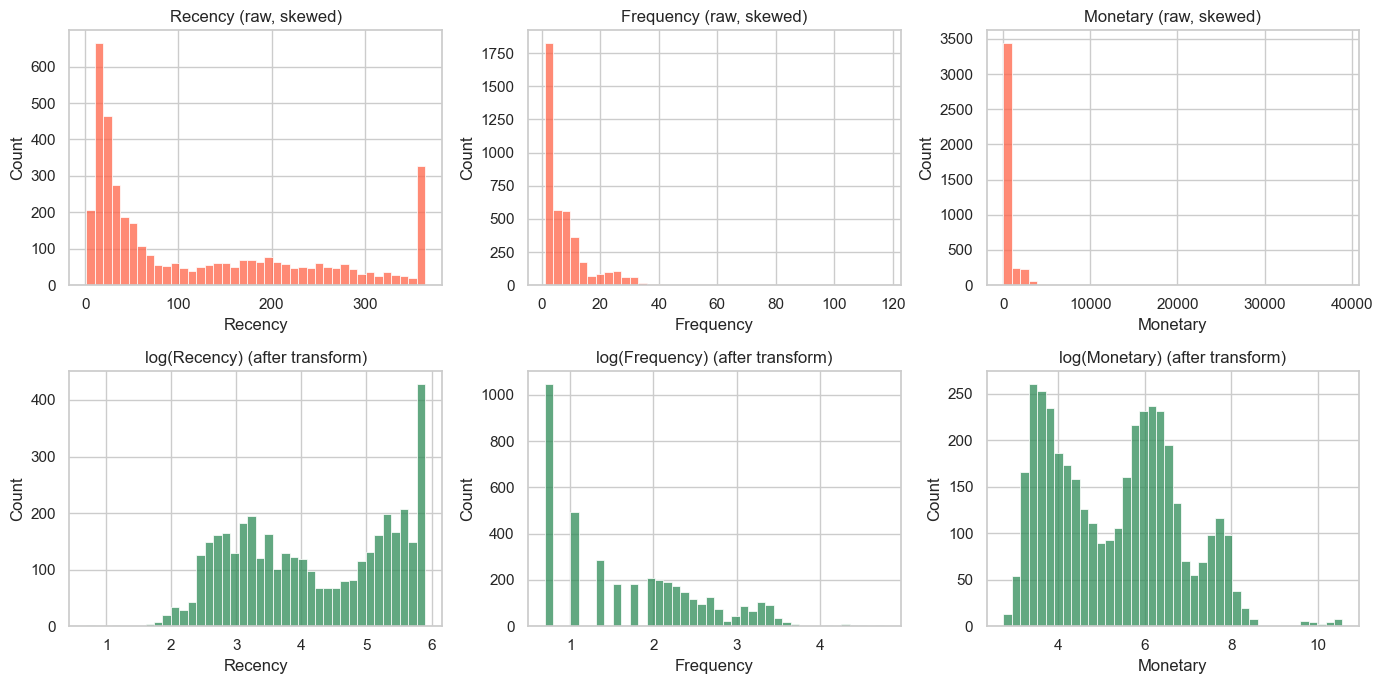

In [4]:
# RFM data is heavily right-skewed -> log transform, then scale (K-Means & DBSCAN use distance).
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for i, c in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[c], bins=40, ax=ax[0, i], color="tomato").set_title(f"{c} (raw, skewed)")
    sns.histplot(np.log1p(rfm[c]), bins=40, ax=ax[1, i], color="seagreen").set_title(f"log({c}) (after transform)")
plt.tight_layout(); plt.savefig("fig1_distributions.png", dpi=130); plt.show()

X_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
X = StandardScaler().fit_transform(X_log)

## Step 3 — PCA
Reduces 3 features to 2 while keeping most variance. PC1 ≈ "overall customer value", PC2 ≈ "recency". The *loadings* table shows what each PC means.

In [5]:
pca_full = PCA().fit(X)
ev = pca_full.explained_variance_ratio_
print("=== STEP 3: PCA ===")
print("Explained variance per component:", ev.round(3))
print("Cumulative:", ev.cumsum().round(3))
print("Loadings (rows = PCs, cols = R, F, M):")
print(pd.DataFrame(pca_full.components_, columns=["Recency", "Frequency", "Monetary"],
                   index=["PC1", "PC2", "PC3"]).round(3), "\n")

pca = PCA(n_components=2, random_state=RNG)
X_pca = pca.fit_transform(X)

=== STEP 3: PCA ===
Explained variance per component: [0.745 0.248 0.007]
Cumulative: [0.745 0.993 1.   ]
Loadings (rows = PCs, cols = R, F, M):
     Recency  Frequency  Monetary
PC1   -0.415      0.642     0.645
PC2    0.910      0.305     0.283
PC3    0.015     -0.704     0.710 



## Step 4 — K-Means
Choose k with **elbow** (inertia), **silhouette** (higher = better) and **Davies-Bouldin** (lower = better). k=4 and k=5 score almost equally; we pick **k=5** because it separates *at-risk* from *lost* customers (more useful for marketing).

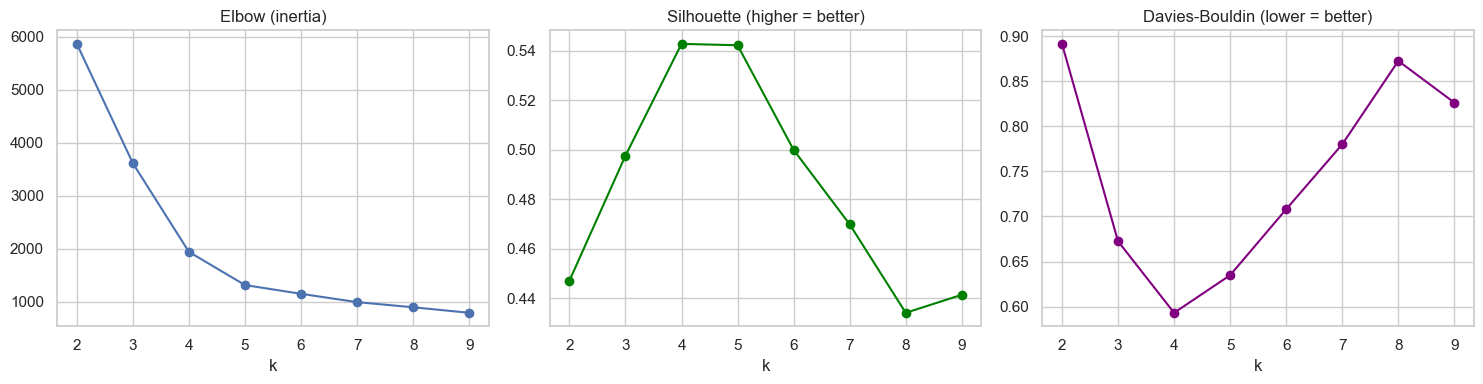

=== STEP 4: K-MEANS ===
 k  inertia  silhouette  davies_bouldin
 2   5864.6       0.447           0.891
 3   3610.1       0.498           0.673
 4   1937.0       0.543           0.593
 5   1311.0       0.542           0.635
 6   1145.9       0.500           0.708
 7    988.8       0.470           0.780
 8    891.6       0.434           0.872
 9    787.3       0.441           0.826


In [6]:
ks = range(2, 10)
inertia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RNG).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
    dbi.append(davies_bouldin_score(X, km.labels_))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Elbow (inertia)", xlabel="k")
ax[1].plot(ks, sil, "o-", color="green"); ax[1].set(title="Silhouette (higher = better)", xlabel="k")
ax[2].plot(ks, dbi, "o-", color="purple"); ax[2].set(title="Davies-Bouldin (lower = better)", xlabel="k")
plt.tight_layout(); plt.savefig("fig2_choose_k.png", dpi=130); plt.show()

print("=== STEP 4: K-MEANS ===")
print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1),
                    "silhouette": np.round(sil, 3), "davies_bouldin": np.round(dbi, 3)}).to_string(index=False))

In [7]:
K = 5   # chosen: business-interpretable AND silhouette is competitive (see report)
km = KMeans(n_clusters=K, n_init=10, random_state=RNG).fit(X)
rfm["KMeans"] = km.labels_
print(f"\nChosen k = {K}; silhouette = {silhouette_score(X, km.labels_):.3f}\n")


Chosen k = 5; silhouette = 0.542



## Step 5 — DBSCAN
Density-based: no k needed, finds arbitrary shapes, labels outliers as **-1 (noise)**. `eps` is chosen at the knee of the k-distance graph; `min_samples` = 2 × dimensions = 6.

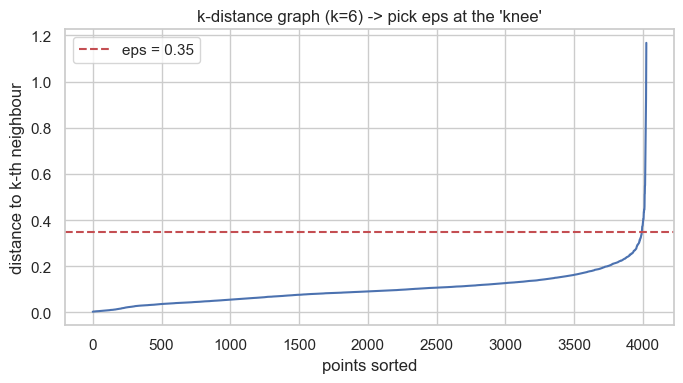

=== STEP 5: DBSCAN ===
eps=0.35, min_samples=6 -> clusters found: 3, noise points: 18 (0.4%)
Silhouette (excluding noise): 0.265
DBSCAN
-1      18
 0    2948
 1    1049
 2      10 



In [8]:
min_samples = 6   # rule of thumb: 2 x dimensions (=6)
nn = NearestNeighbors(n_neighbors=min_samples).fit(X)
kdist = np.sort(nn.kneighbors(X)[0][:, -1])
plt.figure(figsize=(7, 4)); plt.plot(kdist)
plt.axhline(0.35, color="r", ls="--", label="eps = 0.35")
plt.title(f"k-distance graph (k={min_samples}) -> pick eps at the 'knee'")
plt.ylabel("distance to k-th neighbour"); plt.xlabel("points sorted"); plt.legend()
plt.tight_layout(); plt.savefig("fig3_kdistance.png", dpi=130); plt.show()

EPS = 0.35
db = DBSCAN(eps=EPS, min_samples=min_samples).fit(X)
rfm["DBSCAN"] = db.labels_
n_cl = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_noise = int((db.labels_ == -1).sum())
print("=== STEP 5: DBSCAN ===")
print(f"eps={EPS}, min_samples={min_samples} -> clusters found: {n_cl}, noise points: {n_noise} "
      f"({n_noise / len(rfm):.1%})")
mask = db.labels_ != -1
if n_cl > 1:
    print(f"Silhouette (excluding noise): {silhouette_score(X[mask], db.labels_[mask]):.3f}")
print(rfm["DBSCAN"].value_counts().sort_index().to_string(), "\n")

## Step 6 — Visualise with PCA and t-SNE
PCA = linear, global structure. t-SNE = non-linear, preserves local neighbourhoods (axes/distances have no meaning; used **only** for visualisation, never for clustering).

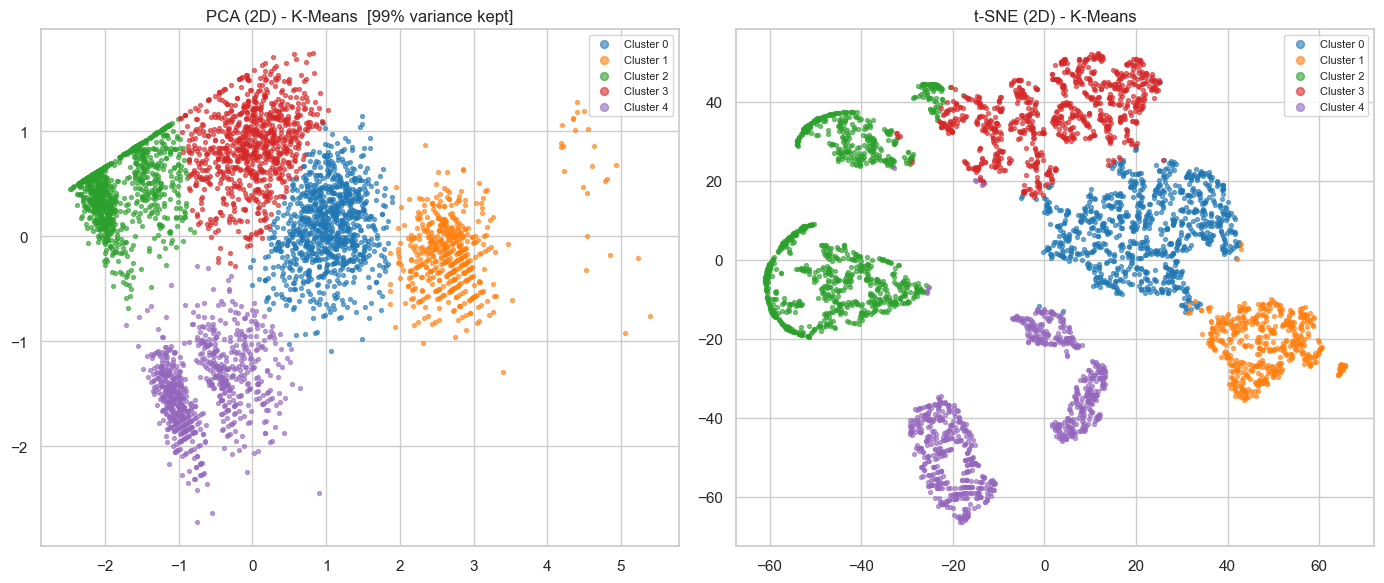

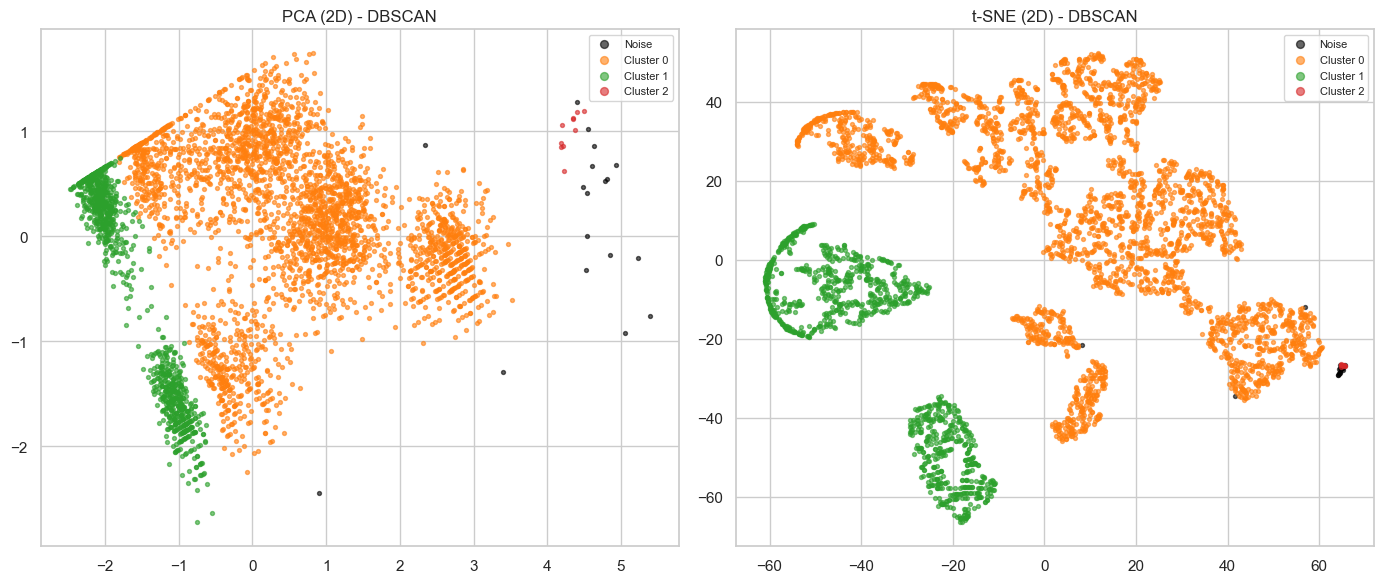

In [9]:
tsne = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=RNG)
X_tsne = tsne.fit_transform(X)

def scatter(ax, emb, labels, title):
    pal = sns.color_palette("tab10", len(set(labels)))
    for i, l in enumerate(sorted(set(labels))):
        m = labels == l
        name = "Noise" if l == -1 else f"Cluster {l}"
        ax.scatter(emb[m, 0], emb[m, 1], s=8, alpha=0.6,
                   c="black" if l == -1 else [pal[i]], label=name)
    ax.set_title(title); ax.legend(markerscale=2, fontsize=8)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
scatter(ax[0], X_pca, rfm["KMeans"].values, f"PCA (2D) - K-Means  [{ev[:2].sum():.0%} variance kept]")
scatter(ax[1], X_tsne, rfm["KMeans"].values, "t-SNE (2D) - K-Means")
plt.tight_layout(); plt.savefig("fig4_kmeans_pca_tsne.png", dpi=130); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
scatter(ax[0], X_pca, rfm["DBSCAN"].values, "PCA (2D) - DBSCAN")
scatter(ax[1], X_tsne, rfm["DBSCAN"].values, "t-SNE (2D) - DBSCAN")
plt.tight_layout(); plt.savefig("fig5_dbscan_pca_tsne.png", dpi=130); plt.show()

## Step 7 — Profile clusters → marketing personas
Average RFM per cluster, share of customers vs share of revenue, then name each persona with simple business rules.

=== STEP 7: CLUSTER PROFILES (K-Means) ===
        Customers  Recency  Frequency  Monetary  TotalRevenue  Share_of_customers_%  Share_of_revenue_%             Persona
KMeans                                                                                                                     
0             909     46.6       10.0     609.8      554331.6                  22.6                20.4      Loyal Regulars
1             511     15.0       27.8    3474.2     1775296.7                  12.7                65.3           Champions
2             980    276.9        1.5      46.9       45992.1                  24.3                 1.7  Lost / Hibernating
3             820    182.8        6.2     348.2      285496.7                  20.4                10.5   At-Risk Customers
4             805     20.3        1.7      69.5       55936.2                  20.0                 2.1     New / Promising 



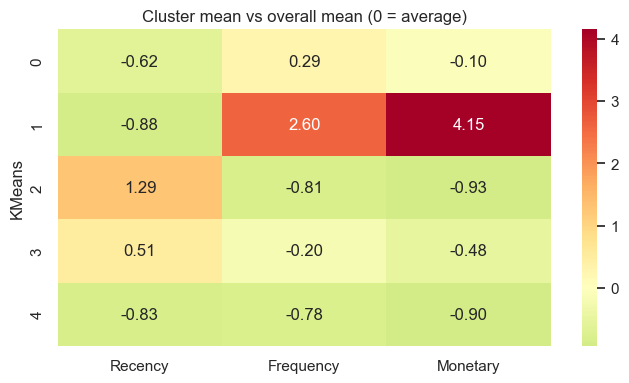

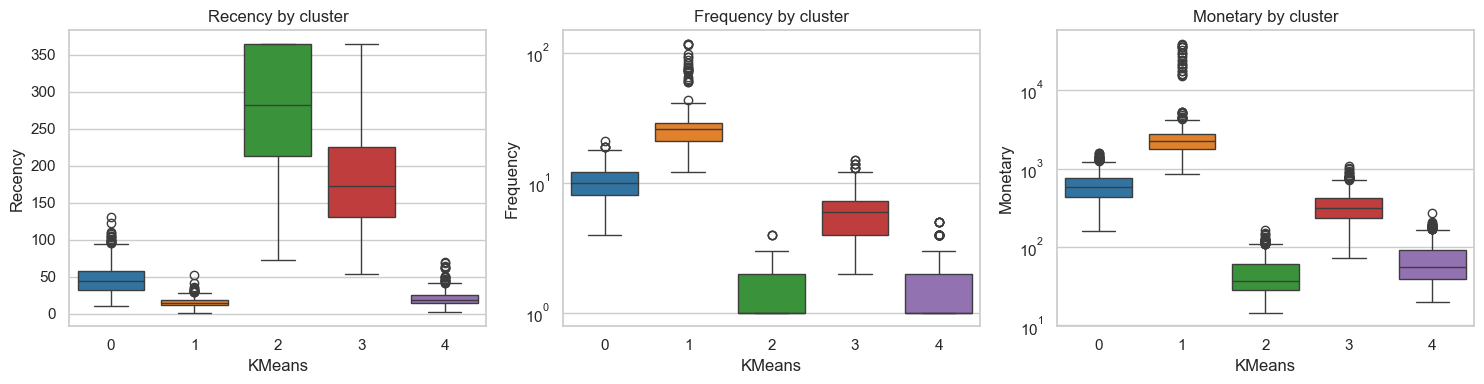

DBSCAN noise points - average RFM:
Recency         11.4
Frequency       74.9
Monetary     22452.2 

Adjusted Rand Index (KMeans vs DBSCAN): 0.117

Done. Files saved.


In [10]:
prof = rfm.groupby("KMeans").agg(
    Customers=("CustomerID", "count"),
    Recency=("Recency", "mean"), Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"), TotalRevenue=("Monetary", "sum"),
).round(1)
prof["Share_of_customers_%"] = (prof.Customers / len(rfm) * 100).round(1)
prof["Share_of_revenue_%"] = (prof.TotalRevenue / prof.TotalRevenue.sum() * 100).round(1)

# Persona naming: simple, explainable business rules on the cluster averages
def name_persona(row):
    if row.Frequency > 20:                          return "Champions"
    if row.Recency < 100 and row.Frequency >= 5:    return "Loyal Regulars"
    if row.Recency < 100:                           return "New / Promising"
    if row.Frequency >= 3:                          return "At-Risk Customers"
    return "Lost / Hibernating"

prof["Persona"] = prof.apply(name_persona, axis=1)
print("=== STEP 7: CLUSTER PROFILES (K-Means) ===")
print(prof.to_string(), "\n")

persona_map = prof["Persona"].to_dict()
rfm["Persona"] = rfm["KMeans"].map(persona_map)

# Heatmap: relative importance of each metric per cluster
rel = (rfm.groupby("KMeans")[["Recency", "Frequency", "Monetary"]].mean()
       / rfm[["Recency", "Frequency", "Monetary"]].mean() - 1)
plt.figure(figsize=(7, 4))
sns.heatmap(rel, annot=True, fmt=".2f", cmap="RdYlGn_r", center=0)
plt.title("Cluster mean vs overall mean (0 = average)")
plt.tight_layout(); plt.savefig("fig6_heatmap.png", dpi=130); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, c in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.boxplot(data=rfm, x="KMeans", y=c, ax=ax[i], palette="tab10", hue="KMeans", legend=False)
    if c != "Recency": ax[i].set_yscale("log")
    ax[i].set_title(f"{c} by cluster")
plt.tight_layout(); plt.savefig("fig7_boxplots.png", dpi=130); plt.show()

# DBSCAN noise = the extreme wholesale buyers?
noise = rfm[rfm.DBSCAN == -1]
print("DBSCAN noise points - average RFM:")
print(noise[["Recency", "Frequency", "Monetary"]].mean().round(1).to_string(), "\n")

# K-Means vs DBSCAN agreement
from sklearn.metrics import adjusted_rand_score
print(f"Adjusted Rand Index (KMeans vs DBSCAN): {adjusted_rand_score(rfm.KMeans, rfm.DBSCAN):.3f}")

rfm.to_csv("rfm_with_clusters.csv", index=False)
prof.to_csv("cluster_profiles.csv")
print("\nDone. Files saved.")

## Conclusion & marketing actions
| Persona | Action |
|---|---|
| **Champions** (~13% of customers, ~65% of revenue) | VIP tier, early access, referrals; avoid unnecessary discounts |
| **Loyal Regulars** | Loyalty points, cross-sell, bundles |
| **At-Risk** | Win-back emails with time-limited coupon |
| **New / Promising** | Welcome series, second-purchase incentive |
| **Lost** | One cheap last-chance email, then stop spending |
| **DBSCAN noise (wholesale)** | Dedicated account manager, B2B pricing |

**Limitations:** synthetic data, RFM ignores product category, K-Means assumes spherical clusters, segments are a snapshot (re-run monthly).